# Exercise 2
The file 'employees_clean_encoded.csv' contains curated data of employees of a certain small company (you generated this file in our last lecture!). In this exercise, we will:
- Open/visualize the data
- Split and preprocess the data
- Create/train/evaluate a $k$NN model for $k$ = 1
- Optimize $k$ manually

### Import the needed libraries/modules/functions

In [48]:
import pandas as pd # Main library to manipulate the data
import numpy as np # Library for general math calculations
import matplotlib.pyplot as plt # library to make very customizable (and nice) plots
from sklearn.model_selection import train_test_split # Split the data
from sklearn.preprocessing import StandardScaler # Preprocessing class
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score # functions for some metrics
from sklearn.neighbors import KNeighborsRegressor # the kNN (class) regressor

### 1) - Open/visualize the data

In [49]:
data = pd.read_csv('employees_clean_encoded.csv') # load the csv file as a DataFrame object named 'data'
data.head() # check the first 5 rows of the DataFrame 'data'

,Age,Experience / years,Highest degree,Salary
0,60.0,3,1,50525.89
1,35.0,7,2,48784.13
2,54.0,2,4,89986.33
3,21.0,2,2,25521.71
4,52.0,19,1,51360.49


In [50]:
data = pd.read_csv('employees_clean_encoded.csv') # load the csv file as a DataFrame object named 'data'
data.head()

,Age,Experience / years,Highest degree,Salary
0,60.0,3,1,50525.89
1,35.0,7,2,48784.13
2,54.0,2,4,89986.33
3,21.0,2,2,25521.71
4,52.0,19,1,51360.49


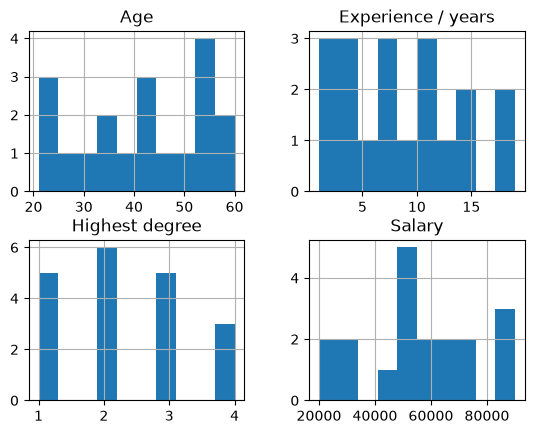

In [51]:
# Let's check the histograms
data.hist(); # plot histograms for all numeric columns of the object 'data'. Note: ";" avoids showing unwanted messages

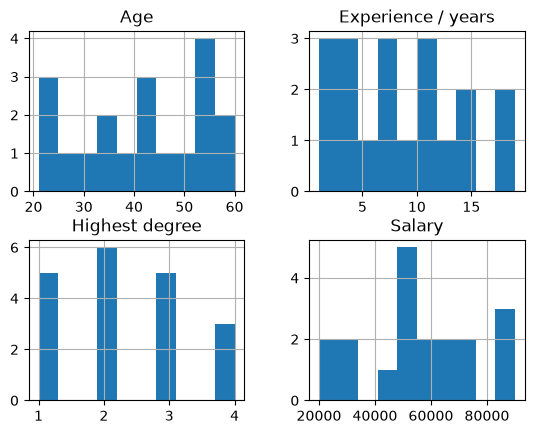

In [52]:
data.hist();

In [53]:
# get statistics on the columns:
data.describe()


,Age,Experience / years,Highest degree,Salary
count,19.000000,19.000000,19.000000,19.000000
mean,41.631579,8.473684,2.315789,56393.062105
std,12.811499,5.551460,1.056863,20674.949568
min,21.000000,1.000000,1.000000,19968.890000
25%,31.500000,3.000000,1.500000,46245.750000
50%,43.000000,8.000000,2.000000,52860.540000
75%,54.000000,12.000000,3.000000,69969.305000
max,60.000000,19.000000,4.000000,89986.330000


### 2) Split the dataset into training (70% of rows) and test (30% of rows) sets
Note: keep the same random state (= 42) for reproducibility

In [54]:
X = data.drop(['Salary'], axis = 1) # Our features (or independent variables), usually called X
# axis = 1 means that we are talking about columns, not rows.

y = data['Salary'] # Our target property (what we want to predict), usually called y
# when Pandas objects have only 1 column (like y above), they are called Series

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42) # Use "help(train_test_split)" to learn more...
# Here, 30 % of the rows are randomly selected and saved as the test set (X_test, y_test), the remainder is the training set

In [55]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape # check their shapes (# rows or samples, # cols)

((13, 3), (6, 3), (13,), (6,))

In [56]:
X_train.head() # check also the other 2D arrays generated!

,Age,Experience / years,Highest degree
3,21.0,2,2
13,25.0,7,1
15,43.0,11,2
17,30.0,14,4
2,54.0,2,4


### 3) Preprocess the data
Columns must have values of similar magnitudes and standard deviations!

In [57]:
scaler = StandardScaler() # create (or instantiate) the scaler object using the StandardScaler() class
scaler.fit(X_train) # calculate and save column averages and stds of X_train inside the object 'scaler'

StandardScaler()

In [58]:
scaler.mean_ # check the average of each feature which is stored in the object scaler 

array([40.76923077,  7.69230769,  2.53846154])

In [59]:
scaler.scale_ # check the standard deviation of each feature

array([11.91736836,  5.41201818,  1.08240364])

In [60]:
dir(scaler) # check ALL attributes and methods available inside object scaler
# Note: In Jupyter notebook, use "scaler." + TAB to see other methods and attributes available for this object

['__annotations__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__sklearn_clone__',
 '__sklearn_tags__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_doc_link_module',
 '_doc_link_template',
 '_doc_link_url_param_generator',
 '_get_class_level_metadata_request_values',
 '_get_doc_link',
 '_get_fitted_attr_html',
 '_get_metadata_request',
 '_get_param_names',
 '_get_params_html',
 '_html_repr',
 '_init_callback_context',
 '_parameter_constraints',
 '_repr_html_',
 '_repr_html_inner',
 '_repr_mimebundle_',
 '_reset',
 '_sklearn_auto_wrap_output_keys',
 '_validate_params',
 'copy',
 'feature_names_in_',
 'fit',
 'fit_transform',


In [61]:
X_train_s = scaler.transform(X_train) # apply the preprocessing to X_train.
# Alternatively, the first two lines above could have been "X_train_s = scaler.fit_transform(X_train)"

In [62]:
X_train_s # it is not a pandas DataFrame anymore, but a 2D array. Compare witht the original values inside 'data'
# Notice that all 3 columns have now the same order of magnitudes, have a zero mean and unit standard deviation!
# Build a new Dataframe (e.g., df = pd.DataFrame(X_train_s)) and check the column histograms

array([[-1.65885875, -1.0517902 , -0.49746834],
       [-1.32321418, -0.12792043, -1.42133811],
       [ 0.1871864 ,  0.61117539, -0.49746834],
       [-0.90365846,  1.16549725,  1.3502712 ],
       [ 1.11020897, -1.0517902 ,  1.3502712 ],
       [ 0.27109754, -0.86701625,  0.42640143],
       [ 0.10327525, -0.31269438,  0.42640143],
       [ 0.94238668,  2.08936702, -1.42133811],
       [-1.40712532, -1.23656415, -0.49746834],
       [ 0.52283097,  0.42640143,  0.42640143],
       [ 1.11020897, -0.86701625,  1.3502712 ],
       [-0.31628046,  1.16549725,  0.42640143],
       [ 1.3619424 ,  0.05685352, -1.42133811]])

<Br><Br>
### Homework: 
Convert the 2D array X_train_s to a pandas DataFrame and make a histogram of the 3 columns separately compare the histograms with the other histograms already done in section 1) above. Use the .describe() method on your new DataFrame and compare the results with those shown in section 1) for the unprocessed dataset.

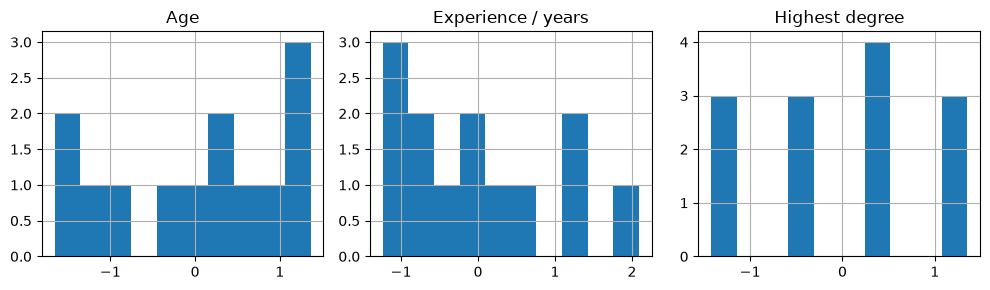

,Age,Experience / years,Highest degree
count,1.300000e+01,1.300000e+01,1.300000e+01
mean,2.049643e-16,-4.857226e-17,6.832142e-17
std,1.040833e+00,1.040833e+00,1.040833e+00
min,-1.658859e+00,-1.236564e+00,-1.421338e+00
25%,-9.036585e-01,-8.670162e-01,-4.974683e-01
50%,1.871864e-01,-1.279204e-01,4.264014e-01
75%,9.423867e-01,6.111754e-01,4.264014e-01
max,1.361942e+00,2.089367e+00,1.350271e+00


In [63]:

# Your code here

# Convert the scaled training array to a DataFrame, preserving the feature names
X_train_s_df = pd.DataFrame(X_train_s, columns=X_train.columns, index=X_train.index)

# Display each feature's histogram separately
X_train_s_df.hist(figsize=(10, 3), bins=10, layout=(1, 3))
plt.tight_layout()
plt.show()

# Summary statistics for the standardized training features
display(X_train_s_df.describe())


<Br><Br>

In [64]:
# Apply the means and standard deviations of X_train (stored inside object scaler) also to X_test:
X_test_s = scaler.transform(X_test) # Note: the object 'scaler' still has stored preprocessing information obtained above.

In [65]:
X_test_s # This is now a 2D array too...and it is now preprocessed (approximately unit variance, zero mean)

array([[ 1.61367583, -0.86701625, -1.42133811],
       [ 1.11020897,  0.9807233 , -0.49746834],
       [ 1.19412011,  0.24162748,  0.42640143],
       [-0.48410275, -0.12792043, -0.49746834],
       [-0.65192503,  0.42640143, -1.42133811],
       [-1.40712532,  2.08936702, -0.49746834]])

<Br><Br>
### 4) Create and train a kNN model with k = 1 nearest neighbor
<Br><Br>

In [66]:
help(KNeighborsRegressor) # check the docstring of this class

Help on class KNeighborsRegressor in module sklearn.neighbors._regression:

class KNeighborsRegressor(sklearn.neighbors._base.KNeighborsMixin, sklearn.base.RegressorMixin, sklearn.neighbors._base.NeighborsBase)
 |  KNeighborsRegressor(
 |      n_neighbors=5,
 |      *,
 |      weights='uniform',
 |      algorithm='auto',
 |      leaf_size=30,
 |      p=2,
 |      metric='minkowski',
 |      metric_params=None,
 |      n_jobs=None
 |  )
 |
 |  Regression based on k-nearest neighbors.
 |
 |  The target is predicted by local interpolation of the targets
 |  associated of the nearest neighbors in the training set.
 |
 |  Read more in the :ref:`User Guide <regression>`.
 |
 |  .. versionadded:: 0.9
 |
 |  Parameters
 |  ----------
 |  n_neighbors : int, default=5
 |      Number of neighbors to use by default for :meth:`kneighbors` queries.
 |
 |  weights : {'uniform', 'distance'}, callable or None, default='uniform'
 |      Weight function used in prediction.  Possible values:
 |
 |      - 

In [67]:
knn = KNeighborsRegressor(n_neighbors = 1) # create a knn regressor object with k = 1

In [68]:
knn.fit(X_train_s, y_train) #  "train" the model (as an exception for "training", in knn the features are only memorized!)
# Note: After trained, the object knn also has plenty of attributes and methods (e.g., .predict())

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [69]:
pred_test = knn.predict(X_test_s) # use the "trained" knn model to perform predictions on the (preprocessed) test set

In [70]:
pred_test # check how the predictions of the target property (= Salary) look like:

array([52860.54, 58323.11, 75749.97, 58323.11, 19968.89, 61393.36])

In [71]:
y_test # check the corresponding true values of the target (the comparison is not good, but it is also not too bad!)

0     50525.89
5     65458.17
11    84949.74
1     48784.13
8     31411.39
16    43707.37
Name: Salary, dtype: float64

<Br><Br>
### 5) Evaluate the model
Were the predictions good or bad? From the two cells above, they seemed to be bad. Let's quantify this goodness using our regression metrics!
<Br><Br>

In [72]:
mae = mean_absolute_error(y_test, pred_test) # mean absolute error between true and predicted values
mse = mean_squared_error(y_test, pred_test) # mean squared error between true and predicted values
r2 = r2_score(y_test, pred_test) # mean squared error between true and predicted values
print(f"MAE: {round(mae)}, MSE: {round(mse)}, R2: {r2:.2f}") # note, I am using f-strings to insert existing variables inside strings

MAE: 9556, MSE: 112618771, R2: 0.61


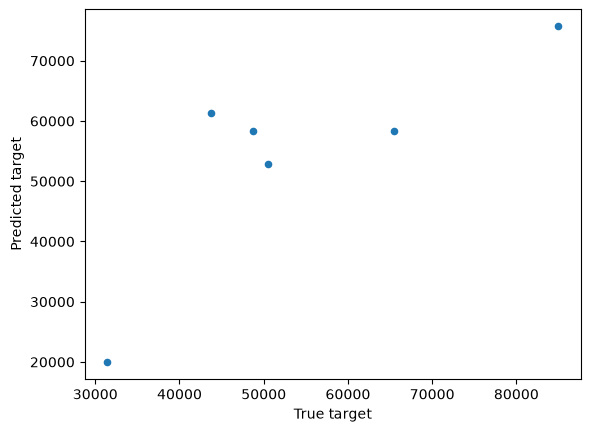

In [73]:
# Let's make a parity plot (not the most beautiful plot we did, but it is straight-forward to do in pandas!)

targets = pd.DataFrame() # create a new and empty pandas DataFrame
targets['True target'] = y_test # create a new column named 'True target"
targets['Predicted target'] = pred_test # create a second column named 'Predicted target"
targets.plot(x='True target', y='Predicted target', kind='scatter'); # plot the data. Do points fall in the diagonal (45 degrees line)? 
# note the semicolon (;) in the last command line of this cell (it prevents annoying warning/verbosity messages)  

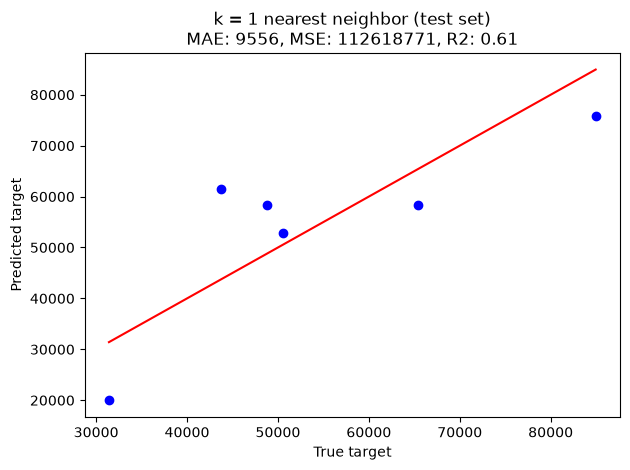

In [74]:
# Let's use matplotlib to make a nicer parity plot

plt.plot(y_test, pred_test, 'bo') # plot true versus predicted target, use blue circles ('bo')

low, high = y_test.min(), y_test.max() # minimum and maximum true values (for plotting the red line)
plt.plot([low, high], [low, high], 'r-') # plot a red continuous line using the extreme values of the true target

plt.xlabel('True target') # x label
plt.ylabel('Predicted target') # y label
plt.title(f"k = 1 nearest neighbor (test set)\nMAE: {round(mae)}, MSE: {round(mse)}, R2: {r2:.2f}"); # Title ("\n" starts a new line)

plt.tight_layout() # never forget this line: it avoids cuts and/or overlaps among graphical elements in the plot!

plt.savefig('my_fig_name.png', dpi = 600) # we can also save our parity plot to a png image with a resolution of 600 dots-per-inch

<Br><Br>

### 6) Optimize the hyperparameter $k$ (in your $k$NN model)
Copy all your code lines above (from dataset splitting to the final knn metrics) to a function.
Then:
- Calculate MSE and R2 for predictions on the test set for different numbers of nearest neighbors (parameter n_neighbors inside the
class KNeighborsRegression()).
- Plot these metrics (y axis) against the number of neighbors (X axis) and check what is the best $k$ for your $k$NN model according to the current conditions (dataset splitting, metrics used, preprocessing, etc) adopted.
- Show the parity plot of the best model.


In [75]:
def knn_metrics(k):
    """
    This function trains a kNN model with 'k' (= integer) nearest neighbors and outputs the metrics 
    (MSE, R2) for predictions on the test set. The dataset (X and y) was defined outside this function, being
    therefore global variables.

    How to use this function:
    (e.g., for getting the metrics for 2 nearest neighbors):

    >>> mse, r2 = knn_metrics(2)
    
    """
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state = 42)

    # Your code here (preprocessing)
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)
    
    knn = KNeighborsRegressor(n_neighbors = k) # the input 'k' (= integer) is used here!

    # your code here... (train the model, perform predictions, calculate metrics)
    knn.fit(X_train_s, y_train)
    pred_test = knn.predict(X_test_s)

    mse = mean_squared_error(y_test, pred_test)
    r2 = r2_score(y_test, pred_test)
    
    return mse, r2

In [76]:
res = []
for i in range(1,11): # from 1 to 10 nearest neighbors
    mse, r2 = knn_metrics(i) # calculate the metrics (is your function ready to go?)
    res.append([mse,r2]) # append the results to the list res
    print(f"k = {i} nearest neighbor (test set)\nMSE: {round(mse)}, R2: {r2:.2f}\n") # print  something in the screen
res = np.array(res).reshape(-1,2) # make an array out of it to plot in the next cell

k = 1 nearest neighbor (test set)
MSE: 112618771, R2: 0.61

k = 2 nearest neighbor (test set)
MSE: 194077339, R2: 0.33

k = 3 nearest neighbor (test set)
MSE: 180033633, R2: 0.38

k = 4 nearest neighbor (test set)
MSE: 130117711, R2: 0.55

k = 5 nearest neighbor (test set)
MSE: 98672841, R2: 0.66

k = 6 nearest neighbor (test set)
MSE: 121593880, R2: 0.58

k = 7 nearest neighbor (test set)
MSE: 148790122, R2: 0.49

k = 8 nearest neighbor (test set)
MSE: 128451268, R2: 0.56

k = 9 nearest neighbor (test set)
MSE: 115691154, R2: 0.60

k = 10 nearest neighbor (test set)
MSE: 129784172, R2: 0.55



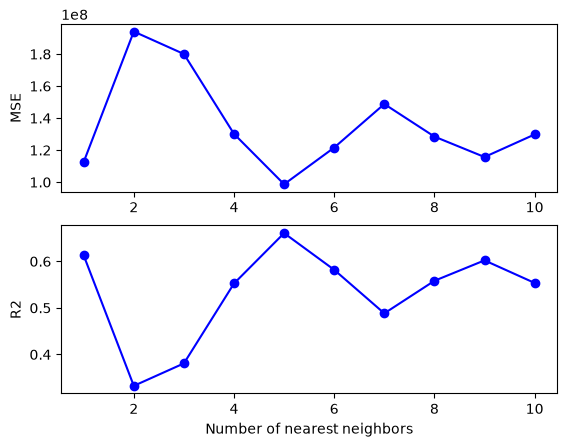

In [77]:
# Show the evolution of metrics for different numbers of nearest neighbors

neighbors = [i for i in range(1,11)]

plt.subplot(2,1,1) # grid of (2 rows, 1 col), subplot number 1
plt.plot(neighbors, res[:,0], '-bo' ) # neighbors = X axis, mse = y axis
plt.ylabel('MSE')

plt.subplot(2,1,2) # grid of (2 rows, 1 col), subplot number 2
plt.plot(neighbors, res[:,1], '-bo' ) # neighbors = X axis, r2 = y axis
plt.ylabel('R2')
plt.xlabel('Number of nearest neighbors');

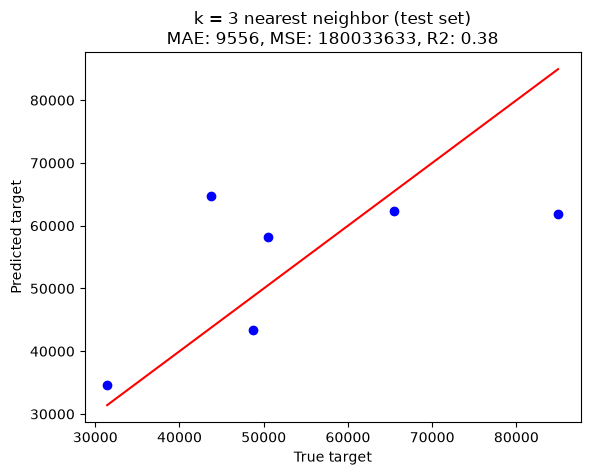

In [78]:
# Show the parity plot for the best kNN model

best_k = 3 # Your best number of nearest neighbors here! (e.g., best_n = 2)

knn = KNeighborsRegressor(n_neighbors = best_k) # Best model


 # the input 'k' (= integer) is used here!

    # your code here... (train the model, perform predictions, calculate metrics)

knn.fit(X_train_s, y_train)
pred_test = knn.predict(X_test_s)

mse = mean_squared_error(y_test, pred_test)
r2 = r2_score(y_test, pred_test)



# Let's use matplotlib to make a nicer parity plot
plt.plot(y_test, pred_test, 'bo') # plot true versus predicted target, use blue circles ("bo")

low, high = y_test.min(), y_test.max() # minimum and maximum true values
plt.plot([low, high], [low, high], 'r-') # plot a red continuous line using the extreme values of the true target

plt.xlabel('True target') # x label
plt.ylabel('Predicted target') # y label
plt.title(f"k = {best_k} nearest neighbor (test set)\nMAE: {round(mae)}, MSE: {round(mse)}, R2: {r2:.2f}"); # Title

In [79]:
def knn_plot(i):
    best_k = i # Your best number of nearest neighbors here! (e.g., best_n = 2)

    knn = KNeighborsRegressor(n_neighbors = best_k) # Best model


    # the input 'k' (= integer) is used here!

        # your code here... (train the model, perform predictions, calculate metrics)

    knn.fit(X_train_s, y_train)
    pred_test = knn.predict(X_test_s)

    mse = mean_squared_error(y_test, pred_test)
    r2 = r2_score(y_test, pred_test)



    # Let's use matplotlib to make a nicer parity plot
    plt.plot(y_test, pred_test, 'bo') # plot true versus predicted target, use blue circles ("bo")

    low, high = y_test.min(), y_test.max() # minimum and maximum true values
    plt.plot([low, high], [low, high], 'r-') # plot a red continuous line using the extreme values of the true target

    plt.xlabel('True target') # x label
    plt.ylabel('Predicted target') # y label
    plt.title(f"k = {best_k} nearest neighbor (test set)\nMAE: {round(mae)}, MSE: {round(mse)}, R2: {r2:.2f}"); # Title



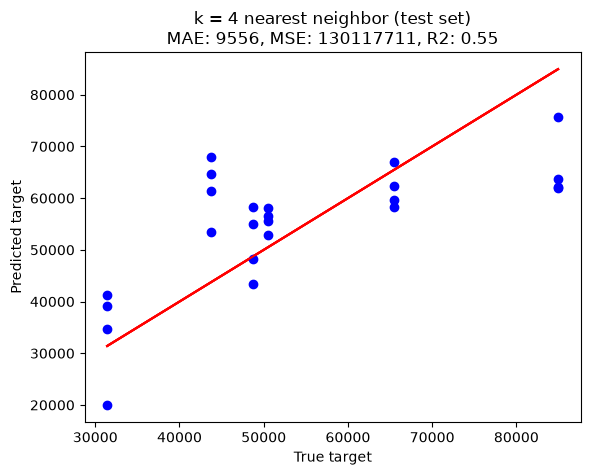

In [80]:
    for i in range(1, 5):
        knn_plot(i);

<Br><Br>
# CHALLENGE
The optimal value of $k$ nearest neighbors (determined above) was based on one specific splitting (random_state = 42 and 30% of the data for the test set). The best way of optimizing hyperparameters is, however, to use cross-validation within the training set. Another way to do that, which is still acceptable and more intuitive (and easier to implement!), is to consider e.g. 10 different random splittings by using a different random seed each time inside the function train_test_split(). TASK: Use this easier approach to decide what is the best number of nearest neighbors ($k$) for your model. Here, for each value of $k$ used ($k=1-10$), you would repeat the model evaluation 10 different times by initially splitting the dataset with 10 different random seeds (random seeds = [11, 13, 17, 19, 23, 29, 37, 43, 47, 51]). Note: Because hyperparameter optimization is always performed using only the training set, for simplicity (and because we don't have really many data points), we assume here that the provided dataset (X and y) is actually our training set, so that we split it each time into 'training' and 'validation' sets.

In [81]:
def knn_metrics(k, seed):
    """
    This function splits my dataset into training and validation sets using the provided 'seed', preprocess the data, then trains a KNN 
    model with 'k' (= integer) nearest neighbors and outputs the metrics (MSE, R2) for predictions on the validation set
    
    How to use this function:

    For 3 nearest neighbors and a random seed of 19:
    >>> mse, r2 = knn_metrics(3, 19)

    """
    # We assume that X and y are global variables defined in previous cells and therefore available
    # inside this function. No need to redefine (or load) them here.
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state = seed)
    
    
    # Your code here (preprocess training and test sets)
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)

    
    knn = KNeighborsRegressor(n_neighbors = k) # the input 'n' (=integer) is used here!

    
    # Your code continues here (train the model, perform predictions, get metrics (mse and r2)

    knn.fit(X_train_s, y_train)
    pred_test = knn.predict(X_test_s)
    
    mse = mean_squared_error(y_test, pred_test)
    r2 = r2_score(y_test, pred_test)
    
    
    return mse, r2

In [82]:
myseeds = [11, 13, 17, 19, 23, 29, 37, 43, 47, 51]
results = {} # empty dictionary. The keys will be the k value (number of nearest neighbors)
for k in range(1,11): # 10 nearest neighbors
    for seed in myseeds:
        mses, r2s = [], [] # create empty lists to store the metrics
        mse, r2 = knn_metrics(k, seed) # run your function to get MSE and R2
        mses.append(mse) # append mse to list mses
        r2s.append(r2) # append mse to list mses
    mse_avg = np.mean(mses) # calculate the average of MSE for all random seeds
    r2_avg = np.mean(r2s) # calculate the average of R2 for all random seeds
    results[k] = {'mse': round(mse_avg), 'r2': round(r2_avg, 2)} # add averages to the main (results) dictionary

In [83]:
results # check your results

{1: {'mse': 325486712, 'r2': np.float64(-0.33)},
 2: {'mse': 229506437, 'r2': np.float64(0.06)},
 3: {'mse': 241052696, 'r2': np.float64(0.01)},
 4: {'mse': 264866746, 'r2': np.float64(-0.08)},
 5: {'mse': 195874609, 'r2': np.float64(0.2)},
 6: {'mse': 204592365, 'r2': np.float64(0.16)},
 7: {'mse': 223081940, 'r2': np.float64(0.09)},
 8: {'mse': 274771051, 'r2': np.float64(-0.12)},
 9: {'mse': 345645746, 'r2': np.float64(-0.41)},
 10: {'mse': 407587215, 'r2': np.float64(-0.67)}}